In [1]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_RAW = ROOT / "data" / "raw"              # AmesHousing.csv (fisierul original, nu e in Git)
DATA_PROCESSED = ROOT / "data" / "processed"  # df.csv, df_fe.csv (generate de notebook-uri, nu sunt in Git)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "src"))         # ca sa functioneze `from common import ...`

In [2]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from common import make_classes, build_features, evaluate

df = pd.read_csv(DATA_PROCESSED / "df_fe.csv")

print("Dimensiunea dataset-ului:", df.shape)
display(df.head())


Dimensiunea dataset-ului: (2930, 96)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,YearsSinceRemod,Remodeled,TotalBath,TotalPorchSF,HasPool,HasFireplace,Has2ndFlr,HasBsmt,QualxLivArea,LivAreaPerRoom
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,50,0,2.0,272,0,1,0,1,9936,236.571429
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,49,0,1.0,260,0,0,0,1,4480,179.200000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,52,0,1.5,429,0,0,0,1,7974,221.500000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,42,0,3.5,0,0,1,0,1,14770,263.750000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,12,1,2.5,246,0,1,1,1,8145,271.500000


In [3]:

df["PriceClass"] = make_classes(df["SalePrice"])

test_prices = pd.Series([
    99999, 100000,
    129999, 130000,
    179999, 180000,
    249999, 250000,
    399999, 400000
])

expected_classes = [0, 1, 1, 2, 2, 3, 3, 4, 4, 5]
actual_classes = make_classes(test_prices)

assert actual_classes.tolist() == expected_classes
assert set(df["PriceClass"].unique()) == set(range(6))
assert df["PriceClass"].notna().all()

print("Distributia claselor:")
print(df["PriceClass"].value_counts().sort_index())

display(pd.DataFrame({
    "SalePrice": test_prices,
    "PriceClass": actual_classes
}))

print("Verificarea make_classes a trecut.")


Distributia claselor:
PriceClass
0     237
1     509
2    1037
3     686
4     397
5      64
Name: count, dtype: int64


,SalePrice,PriceClass
0,99999,0
1,100000,1
2,129999,1
3,130000,2
4,179999,2
5,180000,3
6,249999,3
7,250000,4
8,399999,4
9,400000,5


Verificarea make_classes a trecut.


In [4]:
from common import build_features


X, y, preprocessor = build_features(df, encoding="onehot")

forbidden_cols = {
    "SalePrice",
    "SalePrice_log",
    "PriceClass",
    "Order",
    "PID"
}

assert len(X) == len(y) == len(df)
assert X.columns.is_unique
assert not X.isna().any().any()
assert not forbidden_cols.intersection(X.columns)
assert set(y.unique()) == set(range(6))
assert np.array_equal(y.to_numpy(), df["PriceClass"].to_numpy())

numeric_X = X.select_dtypes(include="number")
assert np.isfinite(numeric_X.to_numpy(dtype=float)).all()

for col in ["MS SubClass", "Mo Sold"]:
    if col in X.columns:
        assert pd.api.types.is_string_dtype(X[col])

print("Dimensiunea X:", X.shape)
print("Dimensiunea y:", y.shape)
print("Valori lipsa:", X.isna().sum().sum())
print("Coloane duplicate:", X.columns.duplicated().sum())
print("Coloane interzise:", forbidden_cols.intersection(X.columns))

print("\nVerificarea build_features a trecut.")



Dimensiunea X: (2930, 92)
Dimensiunea y: (2930,)
Valori lipsa: 0
Coloane duplicate: 0
Coloane interzise: set()

Verificarea build_features a trecut.


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

validation_preprocessor = clone(preprocessor)

X_train_encoded = validation_preprocessor.fit_transform(X_train)
X_test_encoded = validation_preprocessor.transform(X_test)

assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert X_train_encoded.shape[0] == len(X_train)
assert X_test_encoded.shape[0] == len(X_test)
assert X_train_encoded.shape[1] == X_test_encoded.shape[1]
assert np.isfinite(X_train_encoded).all()
assert np.isfinite(X_test_encoded).all()
assert set(y_train.unique()) == set(range(6))
assert set(y_test.unique()) == set(range(6))

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistributia claselor in train:")
print(y_train.value_counts().sort_index())

print("\nDistributia claselor in test:")
print(y_test.value_counts().sort_index())

print("\nTrain encoded:", X_train_encoded.shape)
print("Test encoded:", X_test_encoded.shape)

print("\nverificarea split-ului si encoding-ului a trecut")


Train: (2344, 92)
Test: (586, 92)

Distributia claselor in train:
SalePrice
0    189
1    407
2    830
3    549
4    318
5     51
Name: count, dtype: int64

Distributia claselor in test:
SalePrice
0     48
1    102
2    207
3    137
4     79
5     13
Name: count, dtype: int64

Train encoded: (2344, 299)
Test encoded: (586, 299)

verificarea split-ului si encoding-ului a trecut


In [6]:

model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

assert np.array_equal(model.classes_, np.arange(6))

print("modelul XGBoost a fost antrenat cu succes")


modelul XGBoost a fost antrenat cu succes


Rezultatele modelului:
accuracy: 0.7577
precision_macro: 0.7387
recall_macro: 0.7247
f1_macro: 0.7303
f1_weighted: 0.7570
roc_auc_macro_ovr: 0.9593
average_precision_macro: 0.8230
ROC-AUC per clasa: {0: 0.978, 1: 0.9339, 2: 0.9158, 3: 0.9517, 4: 0.9826, 5: 0.9937}
Average Precision per clasa: {0: 0.8297, 1: 0.7259, 2: 0.8445, 3: 0.8631, 4: 0.9049, 5: 0.7699}
Matricea de confuzie:
 [[ 33  13   2   0   0   0]
 [  7  72  23   0   0   0]
 [  1  19 170  15   1   1]
 [  0   0  25  97  14   1]
 [  0   0   1  11  64   3]
 [  0   0   0   0   5   8]]

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74        48
           1       0.69      0.71      0.70       102
           2       0.77      0.82      0.79       207
           3       0.79      0.71      0.75       137
           4       0.76      0.81      0.79        79
           5       0.62      0.62      0.62        13

    accuracy                           0.76      

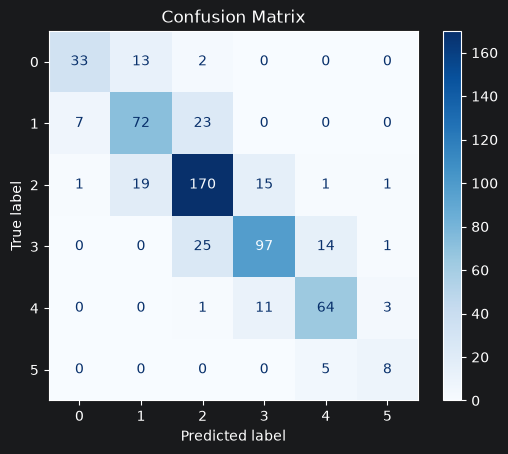

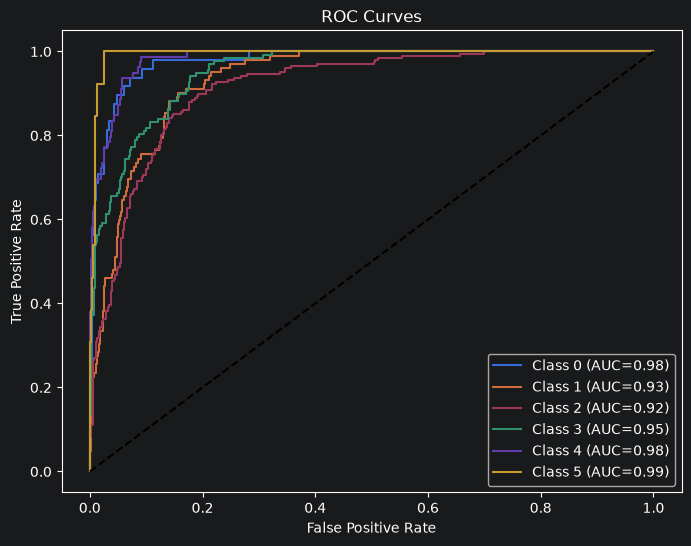

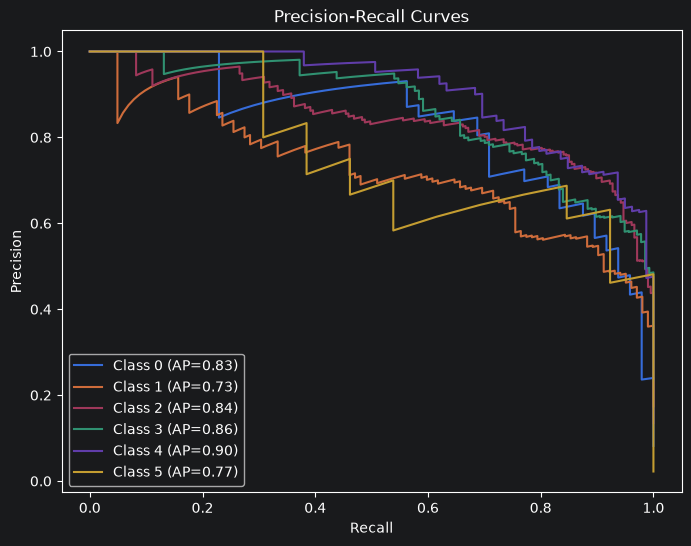


toate verificarile evaluarii au trecut


In [7]:

results = evaluate(
    model,
    X_test,
    y_test,
    show_plots=True
)

expected_metrics = {
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted"
}

assert expected_metrics.issubset(results)

for metric in expected_metrics:
    assert np.isfinite(results[metric])
    assert 0 <= results[metric] <= 1

print("\ntoate verificarile evaluarii au trecut")


In [8]:

def expect_error(func, *args, error_type=ValueError, **kwargs):
    try:
        func(*args, **kwargs)
    except error_type:
        return

    raise AssertionError(
        f"{func.__name__} nu a respins datele invalide."
    )


invalid_prices = [
    pd.Series([-100]),
    pd.Series([np.nan]),
    pd.Series([np.inf]),
    pd.Series(["invalid"])
]

for prices in invalid_prices:
    expect_error(make_classes, prices)

expect_error(
    build_features,
    df.drop(columns=["SalePrice"])
)

expect_error(
    build_features,
    df,
    encoding="invalid"
)

print("Toate verificarile cazurilor-limita au trecut.")


Toate verificarile cazurilor-limita au trecut.


In [9]:
import os
print("Directorul curent:", os.getcwd())

Directorul curent: D:\uni_ 3\ML\lab_1\notebooks\lab2_xgboost


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import make_classes, build_features, evaluate

df = pd.read_csv("df_fe.csv")

df["PriceClass"] = make_classes(df["SalePrice"])

print("Dimensiunea dataset-ului:", df.shape)
display(df[["SalePrice", "PriceClass"]].head())


Dimensiunea dataset-ului: (2930, 97)


,SalePrice,PriceClass
0,215000,3
1,105000,1
2,172000,2
3,244000,3
4,189900,3


In [11]:

class_counts = (
    df["PriceClass"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    df["PriceClass"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

display(class_distribution)

print("Clasa majoritara:", class_counts.idxmax())
print("Clasa minoritara:", class_counts.idxmin())
print("Raport dezechilibru:", round(class_counts.max() / class_counts.min(), 2))


,Count,Percentage (%)
PriceClass,,
0,237,8.09
1,509,17.37
2,1037,35.39
3,686,23.41
4,397,13.55
5,64,2.18


Clasa majoritara: 2
Clasa minoritara: 5
Raport dezechilibru: 16.2


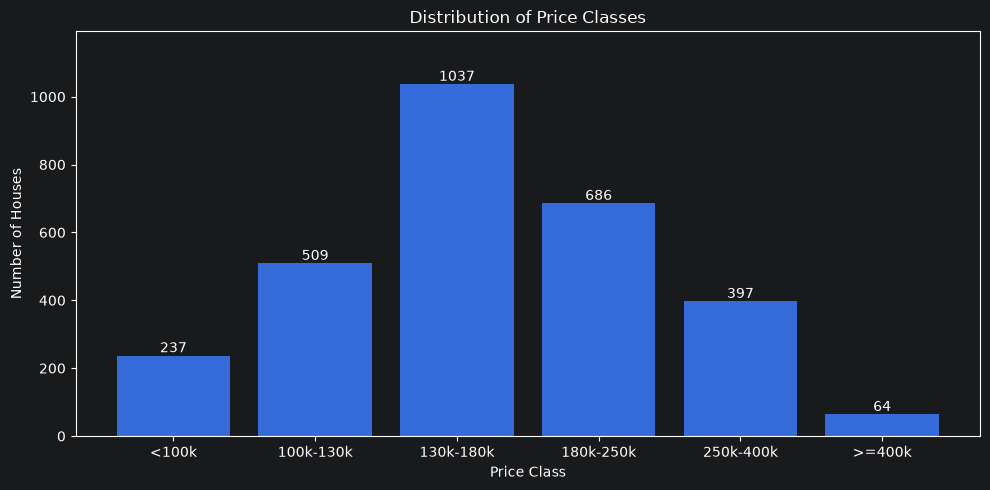

In [12]:

price_labels = [
    "<100k",
    "100k-130k",
    "130k-180k",
    "180k-250k",
    "250k-400k",
    ">=400k"
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    price_labels,
    class_counts.values
)

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        str(count),
        ha="center"
    )

plt.xlabel("Price Class")
plt.ylabel("Number of Houses")
plt.title("Distribution of Price Classes")
plt.ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()


In [13]:

import time

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

from common import build_features

X_onehot, y, preprocessor_onehot = build_features(
    df, encoding="onehot"
)

X_ordinal, _, preprocessor_ordinal = build_features(
    df, encoding="ordinal"
)

assert X_onehot.equals(X_ordinal)

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", len(train_idx))
print("Test:", len(test_idx))


Train: 2344
Test: 586


In [14]:

X_native = X_onehot.copy()

nominal_cols = X_native.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in nominal_cols:
    X_native[col] = X_native[col].astype("category")

assert len(X_native) == len(X_onehot)
assert not X_native.isna().any().any()

print("Coloane categorice native:", len(nominal_cols))
print("Dimensiunea X_native:", X_native.shape)


Coloane categorice native: 43
Dimensiunea X_native: (2930, 92)


In [15]:

X_train = X_onehot.iloc[train_idx]
X_test = X_onehot.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

strategies = {
    "One-hot": Pipeline([
        ("preprocessor", clone(preprocessor_onehot)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Ordinal": Pipeline([
        ("preprocessor", clone(preprocessor_ordinal)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Native": XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        enable_categorical=True,
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model_a2 in strategies.items():
    if name == "Native":
        X_train_current = X_native.iloc[train_idx]
        X_test_current = X_native.iloc[test_idx]
    else:
        X_train_current = X_train
        X_test_current = X_test

    start_time = time.perf_counter()

    model_a2.fit(X_train_current, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model_a2.predict(X_test_current)

    comparison_results.append({
        "Strategy": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Macro F1",
        ascending=False
    ).round(4)
)


,Strategy,Accuracy,Macro F1,Weighted F1,Training Time (s)
2,Native,0.7713,0.7446,0.7711,0.5056
0,One-hot,0.7577,0.7303,0.7570,0.8821
1,Ordinal,0.7526,0.7233,0.7518,0.5205


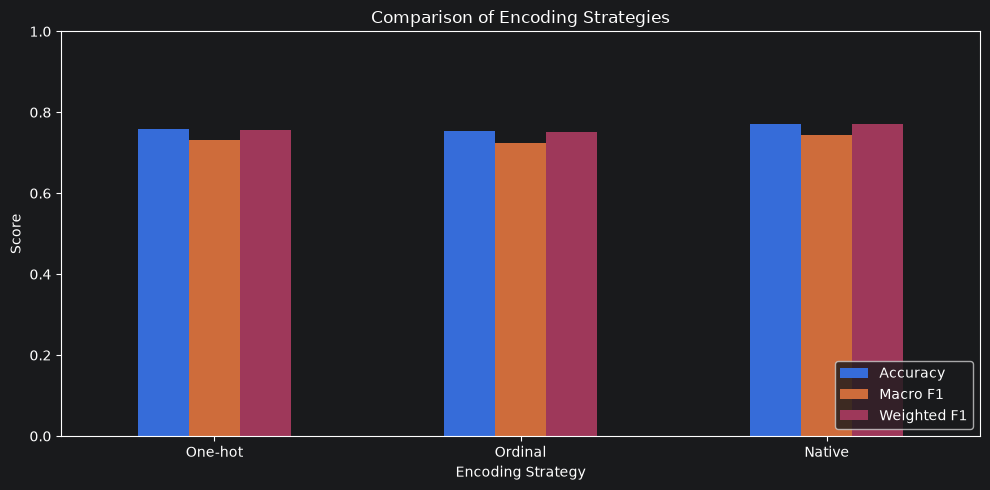

In [16]:

comparison_plot = comparison_df.set_index("Strategy")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Comparison of Encoding Strategies")
ax.set_ylabel("Score")
ax.set_xlabel("Encoding Strategy")
ax.set_ylim(0, 1)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [17]:

df_original = pd.read_csv("df.csv")
df_engineered = pd.read_csv("df_fe.csv")

new_features = sorted(
    set(df_engineered.columns) - set(df_original.columns)
)

print("Dataset original:", df_original.shape)
print("Dataset cu feature engineering:", df_engineered.shape)

print("\nFeature-uri noi:")
for feature in new_features:
    print("-", feature)

assert len(df_original) == len(df_engineered)
assert np.array_equal(
    df_original["SalePrice"].to_numpy(),
    df_engineered["SalePrice"].to_numpy()
)

print("\nVerificarea dataset-urilor a trecut.")


Dataset original: (2930, 83)
Dataset cu feature engineering: (2930, 96)

Feature-uri noi:
- Has2ndFlr
- HasBsmt
- HasFireplace
- HasPool
- HouseAge
- LivAreaPerRoom
- QualxLivArea
- Remodeled
- SalePrice_log
- TotalBath
- TotalPorchSF
- TotalSF
- YearsSinceRemod

Verificarea dataset-urilor a trecut.


In [18]:

common_columns = df_original.columns.intersection(
    df_engineered.columns
)

different_columns = []

for col in common_columns:
    if not df_original[col].equals(df_engineered[col]):
        different_columns.append(col)

print("Coloane comune:", len(common_columns))
print("Coloane cu valori diferite:", different_columns)

assert not different_columns, (
    f"Coloanele comune au valori diferite: {different_columns}"
)

print("Comparatia izoleaza feature-urile suplimentare.")


Coloane comune: 83
Coloane cu valori diferite: []
Comparatia izoleaza feature-urile suplimentare.


In [19]:

X_original, y_original, preprocessor_original = build_features(
    df_original,
    encoding="onehot"
)

X_engineered, y_engineered, preprocessor_engineered = build_features(
    df_engineered,
    encoding="onehot"
)

assert np.array_equal(
    y_original.to_numpy(),
    y_engineered.to_numpy()
)

train_idx, test_idx = train_test_split(
    np.arange(len(y_original)),
    test_size=0.2,
    stratify=y_original,
    random_state=42
)

X_train_original = X_original.iloc[train_idx]
X_test_original = X_original.iloc[test_idx]

X_train_engineered = X_engineered.iloc[train_idx]
X_test_engineered = X_engineered.iloc[test_idx]

y_train_a3 = y_original.iloc[train_idx]
y_test_a3 = y_original.iloc[test_idx]

print("Original X:", X_original.shape)
print("Engineered X:", X_engineered.shape)
print("Train:", len(train_idx))
print("Test:", len(test_idx))


Original X: (2930, 80)
Engineered X: (2930, 92)
Train: 2344
Test: 586


In [20]:

feature_sets = {
    "Without FE": (
        X_train_original,
        X_test_original,
        preprocessor_original
    ),
    "With FE": (
        X_train_engineered,
        X_test_engineered,
        preprocessor_engineered
    )
}

fe_results = []

for name, (X_train_current, X_test_current, prep) in feature_sets.items():

    model_fe = Pipeline([
        ("preprocessor", clone(prep)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()

    model_fe.fit(X_train_current, y_train_a3)

    training_time = time.perf_counter() - start_time

    predictions = model_fe.predict(X_test_current)

    fe_results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_test_a3, predictions),
        "Macro F1": f1_score(
            y_test_a3,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_a3,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

fe_comparison_df = pd.DataFrame(fe_results)

display(fe_comparison_df.round(4))


,Feature Set,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,Without FE,0.7440,0.7155,0.742,0.8233
1,With FE,0.7577,0.7303,0.757,0.8487


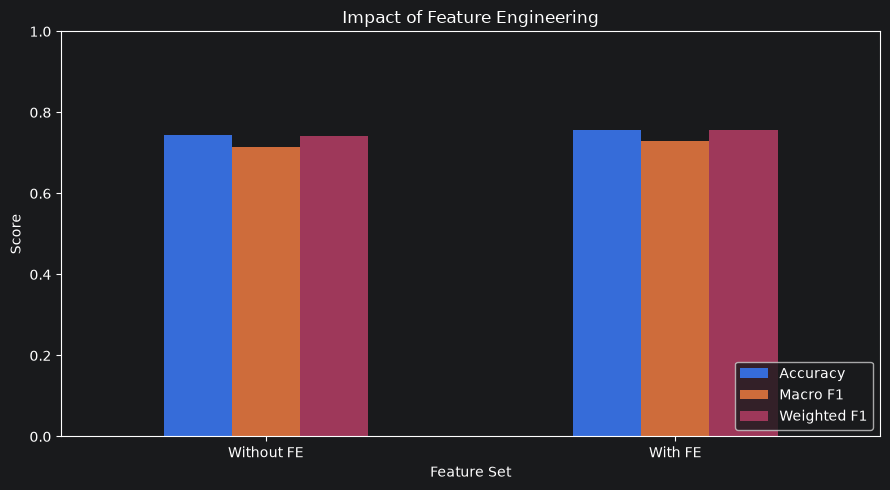

In [21]:

fe_plot = fe_comparison_df.set_index("Feature Set")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = fe_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Impact of Feature Engineering")
ax.set_xlabel("Feature Set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [22]:

without_fe = fe_comparison_df.loc[
    fe_comparison_df["Feature Set"] == "Without FE"
].iloc[0]

with_fe = fe_comparison_df.loc[
    fe_comparison_df["Feature Set"] == "With FE"
].iloc[0]

metrics = ["Accuracy", "Macro F1", "Weighted F1"]

print("Diferenta With FE - Without FE:")

for metric in metrics:
    difference = with_fe[metric] - without_fe[metric]
    print(f"{metric}: {difference:+.4f}")


Diferenta With FE - Without FE:
Accuracy: +0.0137
Macro F1: +0.0148
Weighted F1: +0.0150


In [23]:

partial_houses = df_engineered.loc[
    df_engineered["Sale Condition"] == "Partial"
].copy()

print("Numar total de case Partial:", len(partial_houses))

display(
    partial_houses[
        ["SalePrice", "Gr Liv Area", "Sale Condition"]
    ].sort_values("Gr Liv Area", ascending=False).head(10)
)


Numar total de case Partial: 245


,SalePrice,Gr Liv Area,Sale Condition
1498,160000,5642,Partial
2180,183850,5095,Partial
2181,184750,4676,Partial
2330,545224,3390,Partial
422,485000,3140,Partial
2336,438780,2945,Partial
2332,556581,2868,Partial
2097,424870,2828,Partial
433,582933,2822,Partial
2329,457347,2798,Partial


In [24]:

partial_candidates = df_engineered.loc[
    df_engineered["Sale Condition"].eq("Partial")
    & df_engineered["Gr Liv Area"].gt(3000),
    ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
].copy()

display(
    partial_candidates.sort_values(
        "Gr Liv Area",
        ascending=False
    )
)

print("Numar candidati:", len(partial_candidates))


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial
2330,527210040,545224,3390,Partial
422,528104070,485000,3140,Partial


Numar candidati: 5


In [25]:
import pandas as pd

df_engineered = pd.read_csv("df_fe.csv")
partial_candidates = df_engineered.loc[
    df_engineered["Sale Condition"] == "Partial",
    ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
].copy()

print("Numar case Partial:", len(partial_candidates))

display(
    partial_candidates.sort_values(
        "Gr Liv Area",
        ascending=False
    ).head(20)
)


Numar case Partial: 245


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial
2330,527210040,545224,3390,Partial
422,528104070,485000,3140,Partial
2336,527216050,438780,2945,Partial
2332,527212030,556581,2868,Partial
2097,906340090,424870,2828,Partial
433,528110090,582933,2822,Partial
2329,527210030,457347,2798,Partial


In [26]:


outlier_pids = [
    908154235,
    908154195,
    908154205
]


assert len(outlier_pids) == 3, (
    "Introdu exact cele 3 PID-uri ale outlierilor din L1."
)

outlier_mask = df_engineered["PID"].isin(outlier_pids)

assert outlier_mask.sum() == 3, (
    "Nu au fost identificate exact 3 observatii."
)

print("Outlierii identificati:")
display(
    df_engineered.loc[
        outlier_mask,
        ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
    ]
)


Outlierii identificati:


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial


In [27]:
from common import build_features
from sklearn.model_selection import train_test_split
import numpy as np
X_a4, y_a4, preprocessor_a4 = build_features(
    df_engineered,
    encoding="onehot"
)

train_idx_a4, test_idx_a4 = train_test_split(
    np.arange(len(y_a4)),
    test_size=0.2,
    stratify=y_a4,
    random_state=42
)

train_outlier_mask = outlier_mask.iloc[train_idx_a4].to_numpy()

X_train_full = X_a4.iloc[train_idx_a4]
y_train_full = y_a4.iloc[train_idx_a4]

X_train_clean = X_train_full.loc[
    ~train_outlier_mask
]

y_train_clean = y_train_full.loc[
    ~train_outlier_mask
]

X_test_a4 = X_a4.iloc[test_idx_a4]
y_test_a4 = y_a4.iloc[test_idx_a4]

print("Train cu outlieri:", X_train_full.shape)
print("Train fara outlieri:", X_train_clean.shape)
print("Test comun:", X_test_a4.shape)

print(
    "Outlieri eliminati din train:",
    train_outlier_mask.sum()
)


Train cu outlieri: (2344, 92)
Train fara outlieri: (2343, 92)
Test comun: (586, 92)
Outlieri eliminati din train: 1


In [28]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import time
import pandas as pd


outlier_results = []

training_sets = {
    "With Outliers": (X_train_full, y_train_full),
    "Without Outliers": (X_train_clean, y_train_clean)
}

for name, (X_train_current, y_train_current) in training_sets.items():

    model_a4 = Pipeline([
        ("preprocessor", clone(preprocessor_a4)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()

    model_a4.fit(X_train_current, y_train_current)

    training_time = time.perf_counter() - start_time

    predictions = model_a4.predict(X_test_a4)

    outlier_results.append({
        "Dataset": name,
        "Train Samples": len(X_train_current),
        "Accuracy": accuracy_score(y_test_a4, predictions),
        "Macro F1": f1_score(
            y_test_a4,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_a4,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

outlier_comparison_df = pd.DataFrame(outlier_results)

display(outlier_comparison_df.round(4))


,Dataset,Train Samples,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,With Outliers,2344,0.7577,0.7303,0.7570,0.9305
1,Without Outliers,2343,0.7543,0.7437,0.7534,0.8513


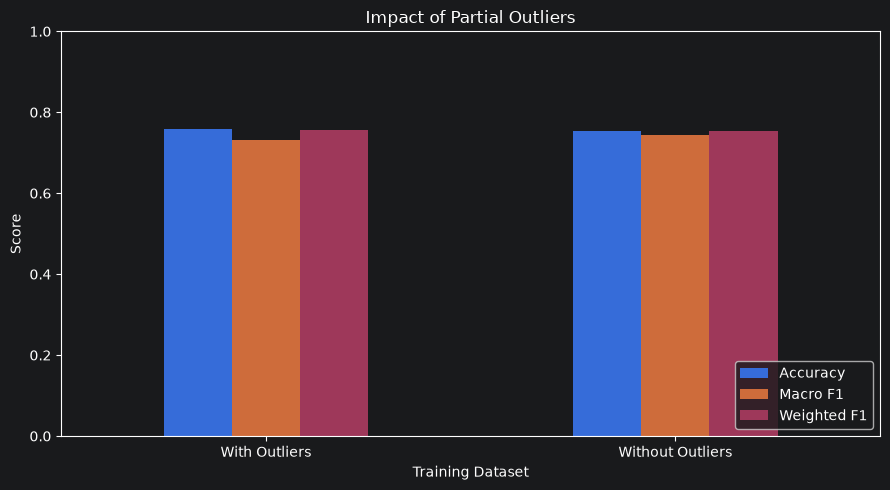

In [29]:

import matplotlib.pyplot as plt

outlier_plot = outlier_comparison_df.set_index("Dataset")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = outlier_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Impact of Partial Outliers")
ax.set_xlabel("Training Dataset")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()



In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

from common import build_features

df_a5 = pd.read_csv("df_fe.csv")

X_a5, y_a5, preprocessor_a5 = build_features(
    df_a5,
    encoding="onehot"
)

split_strategies = [
    ("10% Stratified", 0.10, True),
    ("10% Non-stratified", 0.10, False),
    ("20% Stratified", 0.20, True),
    ("20% Non-stratified", 0.20, False)
]

print("Dataset:", X_a5.shape)
print("Numar clase:", y_a5.nunique())
print("Strategii de comparat:", len(split_strategies))


Dataset: (2930, 92)
Numar clase: 6
Strategii de comparat: 4


In [31]:

split_results = []
class_distributions = []

for name, test_size, stratified in split_strategies:

    X_train, X_test, y_train, y_test = train_test_split(
        X_a5,
        y_a5,
        test_size=test_size,
        random_state=42,
        stratify=y_a5 if stratified else None
    )

    model_a5 = Pipeline([
        ("preprocessor", clone(preprocessor_a5)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()
    model_a5.fit(X_train, y_train)
    training_time = time.perf_counter() - start_time

    predictions = model_a5.predict(X_test)

    split_results.append({
        "Strategy": name,
        "Train Samples": len(X_train),
        "Test Samples": len(X_test),
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions,
            labels=np.arange(6),
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions,
            labels=np.arange(6),
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

    for class_id in range(6):
        class_distributions.append({
            "Strategy": name,
            "Class": class_id,
            "Train Count": int((y_train == class_id).sum()),
            "Test Count": int((y_test == class_id).sum()),
            "Test Percentage": 100 * (y_test == class_id).mean()
        })

split_comparison_df = pd.DataFrame(split_results)
class_distribution_df = pd.DataFrame(class_distributions)

display(split_comparison_df.round(4))


,Strategy,Train Samples,Test Samples,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,10% Stratified,2637,293,0.7338,0.7485,0.7353,0.9237
1,10% Non-stratified,2637,293,0.7406,0.7066,0.7381,0.9046
2,20% Stratified,2344,586,0.7577,0.7303,0.7570,0.8417
3,20% Non-stratified,2344,586,0.7679,0.7492,0.7662,0.8864


In [32]:

test_distribution = class_distribution_df.pivot(
    index="Strategy",
    columns="Class",
    values="Test Count"
)

test_distribution = test_distribution.reindex(
    [strategy[0] for strategy in split_strategies]
)

print("Distributia claselor in seturile de test:")
display(test_distribution)

print("\nProportia claselor in test (%):")

test_percentages = class_distribution_df.pivot(
    index="Strategy",
    columns="Class",
    values="Test Percentage"
)

test_percentages = test_percentages.reindex(
    [strategy[0] for strategy in split_strategies]
)

display(test_percentages.round(2))


Distributia claselor in seturile de test:


Class,0,1,2,3,4,5
Strategy,,,,,,
10% Stratified,24,51,104,68,40,6
10% Non-stratified,25,47,85,79,47,10
20% Stratified,48,102,207,137,79,13
20% Non-stratified,51,92,191,138,94,20



Proportia claselor in test (%):


Class,0,1,2,3,4,5
Strategy,,,,,,
10% Stratified,8.19,17.41,35.49,23.21,13.65,2.05
10% Non-stratified,8.53,16.04,29.01,26.96,16.04,3.41
20% Stratified,8.19,17.41,35.32,23.38,13.48,2.22
20% Non-stratified,8.70,15.70,32.59,23.55,16.04,3.41


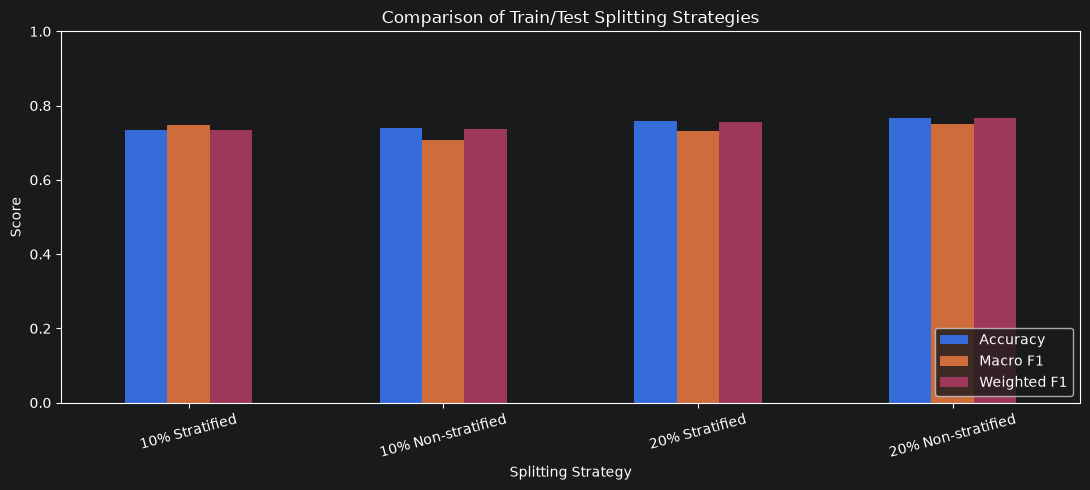

In [33]:

split_plot = split_comparison_df.set_index("Strategy")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = split_plot.plot(
    kind="bar",
    figsize=(11, 5),
    rot=15
)

ax.set_title("Comparison of Train/Test Splitting Strategies")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


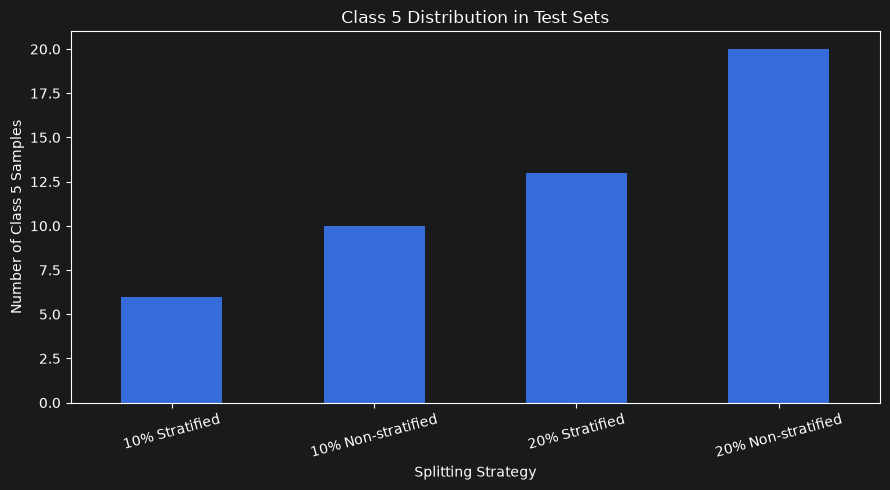

In [34]:


minority_class = class_distribution_df[
    class_distribution_df["Class"] == 5
].copy()

ax = minority_class.plot(
    x="Strategy",
    y="Test Count",
    kind="bar",
    figsize=(9, 5),
    rot=15,
    legend=False
)

ax.set_title("Class 5 Distribution in Test Sets")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Number of Class 5 Samples")

plt.tight_layout()
plt.show()




In [35]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src" / "common.py").exists():
    project_root = project_root.parent.parent

sys.path.insert(0, str(project_root / "src"))

from common import build_features
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier

from common import build_features

df_a6 = pd.read_csv(project_root / "df_fe.csv")

X_a6, y_a6, preprocessor_a6 = build_features(
    df_a6,
    encoding="onehot"
)

cv_strategies = {
    "5-Fold": StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "10-Fold": StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    ),
    "5-Fold Non-Stratified": KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "10-Fold Non-Stratified": KFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )
}

scoring_a6 = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        labels=np.arange(6),
        zero_division=0
    ),
    "weighted_f1": make_scorer(
        f1_score,
        average="weighted",
        labels=np.arange(6),
        zero_division=0
    )
}

print("Dataset:", X_a6.shape)
print("Numar clase:", y_a6.nunique())
print("Strategii CV:", list(cv_strategies.keys()))


Dataset: (2930, 92)
Numar clase: 6
Strategii CV: ['5-Fold', '10-Fold', '5-Fold Non-Stratified', '10-Fold Non-Stratified']


In [36]:

cv_results = []
cv_fold_results = []

for name, cv in cv_strategies.items():

    model_a6 = Pipeline([
        ("preprocessor", clone(preprocessor_a6)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model_a6,
        X_a6,
        y_a6,
        cv=cv,
        scoring=scoring_a6,
        n_jobs=1,
        return_train_score=True,
        error_score="raise"
    )

    cv_results.append({
        "CV Strategy": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Macro F1 Mean": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std(),
        "Weighted F1 Mean": scores["test_weighted_f1"].mean(),
        "Weighted F1 Std": scores["test_weighted_f1"].std(),
        "Train Macro F1": scores["train_macro_f1"].mean(),
        "Fit Time Mean (s)": scores["fit_time"].mean()
    })

    for fold_idx in range(cv.get_n_splits()):
        cv_fold_results.append({
            "CV Strategy": name,
            "Fold": fold_idx + 1,
            "Accuracy": scores["test_accuracy"][fold_idx],
            "Macro F1": scores["test_macro_f1"][fold_idx],
            "Weighted F1": scores["test_weighted_f1"][fold_idx],
            "Train Macro F1": scores["train_macro_f1"][fold_idx]
        })

cv_comparison_df = pd.DataFrame(cv_results)
cv_folds_df = pd.DataFrame(cv_fold_results)

display(cv_comparison_df.round(4))


,CV Strategy,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,Train Macro F1,Fit Time Mean (s)
0,5-Fold,0.7519,0.0144,0.7337,0.0133,0.7495,0.0144,0.9708,0.8593
1,10-Fold,0.7529,0.0207,0.7388,0.0277,0.7511,0.0207,0.9637,0.8975
2,5-Fold Non-Stratified,0.7563,0.0178,0.7436,0.0174,0.7545,0.0179,0.9688,0.8383
3,10-Fold Non-Stratified,0.7485,0.0268,0.7332,0.0400,0.7469,0.0271,0.9640,0.8890


In [37]:

print("Rezultatele fiecarui fold:")

display(
    cv_folds_df.round(4)
)


Rezultatele fiecarui fold:


,CV Strategy,Fold,Accuracy,Macro F1,Weighted F1,Train Macro F1
0,5-Fold,1,0.7577,0.7213,0.7558,0.9743
1,5-Fold,2,0.7679,0.7415,0.7664,0.9682
2,5-Fold,3,0.7423,0.7469,0.7408,0.9716
3,5-Fold,4,0.7628,0.7446,0.7585,0.9690
4,5-Fold,5,0.7287,0.7143,0.7261,0.9707
5,10-Fold,1,0.7713,0.7417,0.7685,0.9643
6,10-Fold,2,0.7543,0.7331,0.7517,0.9658
7,10-Fold,3,0.7782,0.7898,0.7776,0.9626
8,10-Fold,4,0.7474,0.6909,0.7457,0.9633
9,10-Fold,5,0.7509,0.7668,0.7517,0.9647


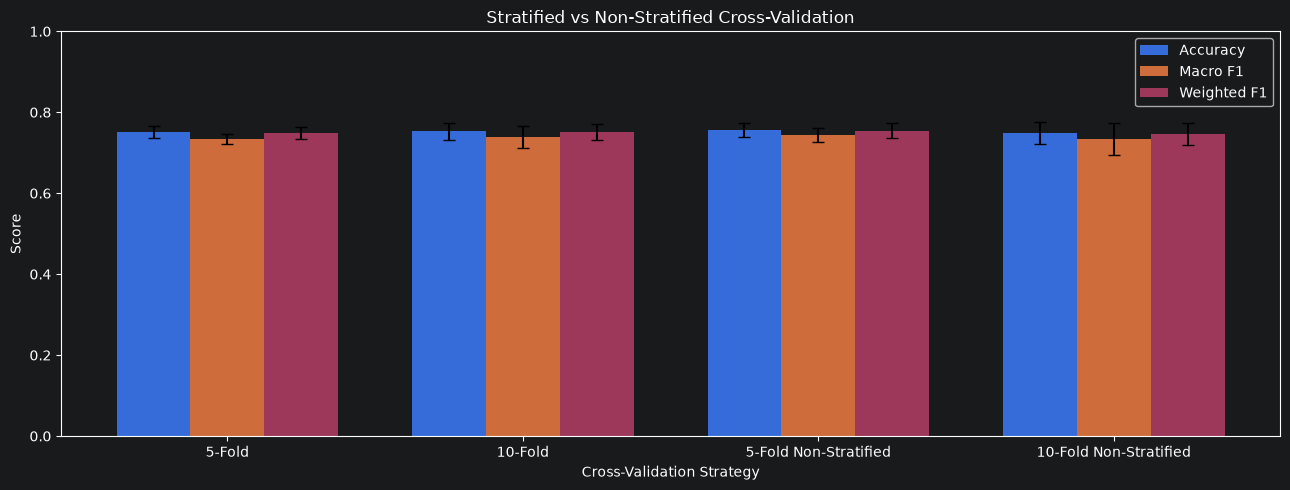

In [38]:

metrics_a6 = [
    ("Accuracy Mean", "Accuracy Std", "Accuracy"),
    ("Macro F1 Mean", "Macro F1 Std", "Macro F1"),
    ("Weighted F1 Mean", "Weighted F1 Std", "Weighted F1")
]

x = np.arange(len(cv_comparison_df))
width = 0.25

fig, ax = plt.subplots(figsize=(13, 5))

for i, (mean_col, std_col, label) in enumerate(metrics_a6):
    ax.bar(
        x + (i - 1) * width,
        cv_comparison_df[mean_col],
        width,
        yerr=cv_comparison_df[std_col],
        capsize=4,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(cv_comparison_df["CV Strategy"])
ax.set_ylim(0, 1)
ax.set_xlabel("Cross-Validation Strategy")
ax.set_ylabel("Score")
ax.set_title("Stratified vs Non-Stratified Cross-Validation")
ax.legend()

plt.tight_layout()
plt.show()


In [39]:

outlier_pids_a6 = [
    908154235,
    908154195,
    908154205
]

outlier_mask_a6 = df_a6["PID"].isin(outlier_pids_a6).to_numpy()

assert len(set(outlier_pids_a6)) == 3
assert outlier_mask_a6.sum() == 3

cv_outliers = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Outlieri identificati:", outlier_mask_a6.sum())
print("Numar fold-uri:", cv_outliers.get_n_splits())


Outlieri identificati: 3
Numar fold-uri: 5


In [40]:

outlier_cv_results = []

for fold_idx, (train_idx, val_idx) in enumerate(
    cv_outliers.split(X_a6, y_a6),
    start=1
):

    X_train_full = X_a6.iloc[train_idx]
    y_train_full = y_a6.iloc[train_idx]

    X_val = X_a6.iloc[val_idx]
    y_val = y_a6.iloc[val_idx]

    train_outlier_mask = outlier_mask_a6[train_idx]

    training_variants = {
        "With Outliers": (
            X_train_full,
            y_train_full
        ),
        "Without Outliers": (
            X_train_full.iloc[~train_outlier_mask],
            y_train_full.iloc[~train_outlier_mask]
        )
    }

    for variant, (X_train_current, y_train_current) in training_variants.items():

        model_outlier_cv = Pipeline([
            ("preprocessor", clone(preprocessor_a6)),
            ("classifier", XGBClassifier(
                objective="multi:softprob",
                num_class=6,
                n_estimators=100,
                max_depth=4,
                learning_rate=0.1,
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            ))
        ])

        model_outlier_cv.fit(
            X_train_current,
            y_train_current
        )

        predictions = model_outlier_cv.predict(X_val)

        outlier_cv_results.append({
            "Fold": fold_idx,
            "Variant": variant,
            "Train Samples": len(X_train_current),
            "Outliers Removed": (
                int(train_outlier_mask.sum())
                if variant == "Without Outliers"
                else 0
            ),
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val,
                predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Weighted F1": f1_score(
                y_val,
                predictions,
                labels=np.arange(6),
                average="weighted",
                zero_division=0
            )
        })

outlier_cv_df = pd.DataFrame(outlier_cv_results)

display(outlier_cv_df.round(4))


,Fold,Variant,Train Samples,Outliers Removed,Accuracy,Macro F1,Weighted F1
0,1,With Outliers,2344,0,0.7577,0.7213,0.7558
1,1,Without Outliers,2341,3,0.7491,0.7184,0.7472
2,2,With Outliers,2344,0,0.7679,0.7415,0.7664
3,2,Without Outliers,2342,2,0.7713,0.7465,0.7698
4,3,With Outliers,2344,0,0.7423,0.7469,0.7408
5,3,Without Outliers,2341,3,0.7457,0.7562,0.7446
6,4,With Outliers,2344,0,0.7628,0.7446,0.7585
7,4,Without Outliers,2343,1,0.7713,0.7675,0.7670
8,5,With Outliers,2344,0,0.7287,0.7143,0.7261
9,5,Without Outliers,2341,3,0.7321,0.7127,0.7291


In [41]:

outlier_cv_summary = outlier_cv_df.groupby("Variant").agg(
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_Std=("Accuracy", "std"),
    Macro_F1_Mean=("Macro F1", "mean"),
    Macro_F1_Std=("Macro F1", "std"),
    Weighted_F1_Mean=("Weighted F1", "mean"),
    Weighted_F1_Std=("Weighted F1", "std")
)

display(outlier_cv_summary.round(4))

print("\nDiferenta medie Without - With:")

for metric in ["Accuracy", "Macro F1", "Weighted F1"]:
    means = outlier_cv_df.groupby("Variant")[metric].mean()

    difference = (
        means["Without Outliers"] -
        means["With Outliers"]
    )

    print(f"{metric}: {difference:+.4f}")


,Accuracy_Mean,Accuracy_Std,Macro_F1_Mean,Macro_F1_Std,Weighted_F1_Mean,Weighted_F1_Std
Variant,,,,,,
With Outliers,0.7519,0.0161,0.7337,0.0149,0.7495,0.0161
Without Outliers,0.7539,0.0171,0.7403,0.0238,0.7516,0.0169



Diferenta medie Without - With:
Accuracy: +0.0020
Macro F1: +0.0065
Weighted F1: +0.0020


In [42]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier

from common import build_features

df_a7 = pd.read_csv("df_fe.csv")

X_a7, y_a7, preprocessor_a7 = build_features(
    df_a7,
    encoding="onehot"
)

cv_a7 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_a7 = Pipeline([
    ("preprocessor", clone(preprocessor_a7)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("Dataset:", X_a7.shape)
print("Numar clase:", y_a7.nunique())
print("Cross-validation: 5-Fold Stratified")


Dataset: (2930, 92)
Numar clase: 6
Cross-validation: 5-Fold Stratified


In [43]:

from sklearn.metrics import make_scorer, f1_score

macro_f1_scorer_a7 = make_scorer(
    f1_score,
    average="macro",
    labels=np.arange(6),
    zero_division=0
)

train_sizes_a7 = np.linspace(0.2, 1.0, 9)

train_sizes_abs, train_scores, validation_scores = learning_curve(
    estimator=model_a7,
    X=X_a7,
    y=y_a7,
    train_sizes=train_sizes_a7,
    cv=cv_a7,
    scoring=macro_f1_scorer_a7,
    shuffle=True,
    random_state=42,
    n_jobs=1,
    error_score="raise"
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

learning_results_df = pd.DataFrame({
    "Training Samples": train_sizes_abs,
    "Train Macro F1 Mean": train_mean,
    "Train Macro F1 Std": train_std,
    "Validation Macro F1 Mean": validation_mean,
    "Validation Macro F1 Std": validation_std,
    "Generalization Gap": train_mean - validation_mean
})

display(learning_results_df.round(4))


,Training Samples,Train Macro F1 Mean,Train Macro F1 Std,Validation Macro F1 Mean,Validation Macro F1 Std,Generalization Gap
0,468,1.0000,0.0000,0.6809,0.0241,0.3191
1,703,1.0000,0.0000,0.6637,0.0548,0.3363
2,937,0.9964,0.0015,0.7004,0.0181,0.2960
3,1172,0.9937,0.0022,0.7152,0.0192,0.2785
4,1406,0.9889,0.0027,0.7103,0.0150,0.2786
5,1640,0.9837,0.0024,0.7221,0.0192,0.2615
6,1875,0.9804,0.0018,0.7300,0.0134,0.2505
7,2109,0.9746,0.0020,0.7269,0.0210,0.2477
8,2344,0.9702,0.0018,0.7301,0.0179,0.2400


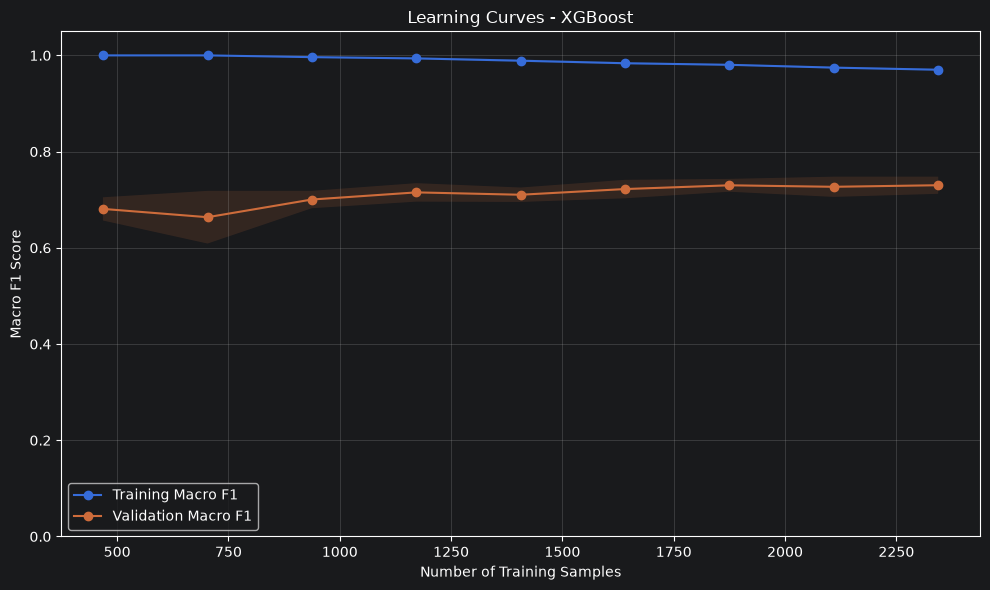

In [44]:

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Training Macro F1"
)

plt.plot(
    train_sizes_abs,
    validation_mean,
    marker="o",
    label="Validation Macro F1"
)

plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes_abs,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1 Score")
plt.title("Learning Curves - XGBoost")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [45]:

final_train_f1 = train_mean[-1]
final_validation_f1 = validation_mean[-1]
final_gap = final_train_f1 - final_validation_f1

print(f"Train Macro F1: {final_train_f1:.4f}")
print(f"Validation Macro F1: {final_validation_f1:.4f}")
print(f"Generalization Gap: {final_gap:.4f}")

print("\nEvolutia scorului de validare:")
print(
    f"Primul punct: {validation_mean[0]:.4f}"
)
print(
    f"Ultimul punct: {validation_mean[-1]:.4f}"
)

if final_gap > 0.10:
    print(
        "\nDiferenta mare intre train si validare "
        "sugereaza overfitting."
    )
else:
    print(
        "\nDiferenta dintre train si validare "
        "este relativ redusa."
    )


Train Macro F1: 0.9702
Validation Macro F1: 0.7301
Generalization Gap: 0.2400

Evolutia scorului de validare:
Primul punct: 0.6809
Ultimul punct: 0.7301

Diferenta mare intre train si validare sugereaza overfitting.


In [46]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier

from common import build_features

df_a8 = pd.read_csv("df_fe.csv")

X_a8, y_a8, preprocessor_a8 = build_features(
    df_a8,
    encoding="onehot"
)

class_counts_a8 = y_a8.value_counts().sort_index()

class_distribution_a8 = pd.DataFrame({
    "Class": class_counts_a8.index,
    "Samples": class_counts_a8.values,
    "Percentage": (
        class_counts_a8.values / len(y_a8) * 100
    )
})

display(class_distribution_a8.round(2))

print(
    "Imbalance ratio:",
    round(class_counts_a8.max() / class_counts_a8.min(), 2)
)


,Class,Samples,Percentage
0,0,237,8.09
1,1,509,17.37
2,2,1037,35.39
3,3,686,23.41
4,4,397,13.55
5,5,64,2.18


Imbalance ratio: 16.2


In [47]:

cv_a8 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

imbalance_results = []
class_results = []

for fold_idx, (train_idx, val_idx) in enumerate(
    cv_a8.split(X_a8, y_a8),
    start=1
):

    X_train = X_a8.iloc[train_idx]
    X_val = X_a8.iloc[val_idx]

    y_train = y_a8.iloc[train_idx]
    y_val = y_a8.iloc[val_idx]

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    for strategy in ["Baseline", "Balanced Weights"]:

        model_a8 = Pipeline([
            ("preprocessor", clone(preprocessor_a8)),
            ("classifier", XGBClassifier(
                objective="multi:softprob",
                num_class=6,
                n_estimators=100,
                max_depth=4,
                learning_rate=0.1,
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            ))
        ])

        if strategy == "Balanced Weights":
            model_a8.fit(
                X_train,
                y_train,
                classifier__sample_weight=sample_weights
            )
        else:
            model_a8.fit(X_train, y_train)

        predictions = model_a8.predict(X_val)

        imbalance_results.append({
            "Fold": fold_idx,
            "Strategy": strategy,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro Precision": precision_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Macro Recall": recall_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Macro F1": f1_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Weighted F1": f1_score(
                y_val, predictions,
                labels=np.arange(6),
                average="weighted",
                zero_division=0
            )
        })

        class_precision = precision_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        class_recall = recall_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        class_f1 = f1_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        for class_id in range(6):
            class_results.append({
                "Fold": fold_idx,
                "Strategy": strategy,
                "Class": class_id,
                "Precision": class_precision[class_id],
                "Recall": class_recall[class_id],
                "F1": class_f1[class_id]
            })

imbalance_results_df = pd.DataFrame(imbalance_results)
class_results_df = pd.DataFrame(class_results)

display(imbalance_results_df.round(4))


,Fold,Strategy,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,Baseline,0.7577,0.7460,0.7077,0.7213,0.7558
1,1,Balanced Weights,0.7304,0.7238,0.7319,0.7221,0.7321
2,2,Baseline,0.7679,0.7779,0.7213,0.7415,0.7664
3,2,Balanced Weights,0.7628,0.7470,0.7638,0.7545,0.7626
4,3,Baseline,0.7423,0.7604,0.7356,0.7469,0.7408
5,3,Balanced Weights,0.7287,0.7280,0.7510,0.7385,0.7292
6,4,Baseline,0.7628,0.7709,0.7285,0.7446,0.7585
7,4,Balanced Weights,0.7406,0.7261,0.7425,0.7327,0.7398
8,5,Baseline,0.7287,0.7340,0.6991,0.7143,0.7261
9,5,Balanced Weights,0.7116,0.7080,0.7257,0.7164,0.7121


In [48]:

imbalance_summary_df = (
    imbalance_results_df
    .groupby("Strategy")
    .agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Macro_Precision_Mean=("Macro Precision", "mean"),
        Macro_Recall_Mean=("Macro Recall", "mean"),
        Macro_F1_Mean=("Macro F1", "mean"),
        Macro_F1_Std=("Macro F1", "std"),
        Weighted_F1_Mean=("Weighted F1", "mean"),
        Weighted_F1_Std=("Weighted F1", "std")
    )
)

display(imbalance_summary_df.round(4))

print("\nDiferenta Balanced - Baseline:")

for metric in ["Accuracy", "Macro Recall", "Macro F1", "Weighted F1"]:
    means = imbalance_results_df.groupby("Strategy")[metric].mean()

    difference = (
        means["Balanced Weights"] - means["Baseline"]
    )

    print(f"{metric}: {difference:+.4f}")


,Accuracy_Mean,Accuracy_Std,Macro_Precision_Mean,Macro_Recall_Mean,Macro_F1_Mean,Macro_F1_Std,Weighted_F1_Mean,Weighted_F1_Std
Strategy,,,,,,,,
Balanced Weights,0.7348,0.0188,0.7266,0.7430,0.7328,0.0149,0.7352,0.0184
Baseline,0.7519,0.0161,0.7578,0.7184,0.7337,0.0149,0.7495,0.0161



Diferenta Balanced - Baseline:
Accuracy: -0.0171
Macro Recall: +0.0246
Macro F1: -0.0009
Weighted F1: -0.0144


In [49]:

class_summary_df = (
    class_results_df
    .groupby(["Strategy", "Class"])
    .agg(
        Precision_Mean=("Precision", "mean"),
        Recall_Mean=("Recall", "mean"),
        F1_Mean=("F1", "mean")
    )
    .reset_index()
)

display(class_summary_df.round(4))

class_5_comparison = (
    class_summary_df[class_summary_df["Class"] == 5]
    .set_index("Strategy")
)

print("\nRezultatele pentru clasa 5:")
display(class_5_comparison.round(4))


,Strategy,Class,Precision_Mean,Recall_Mean,F1_Mean
0,Balanced Weights,0,0.7355,0.7131,0.7213
1,Balanced Weights,1,0.6197,0.6759,0.6455
2,Balanced Weights,2,0.7899,0.7252,0.7554
3,Balanced Weights,3,0.7312,0.7506,0.7401
4,Balanced Weights,4,0.7802,0.8136,0.7961
5,Balanced Weights,5,0.7029,0.7795,0.7386
6,Baseline,0,0.7677,0.6582,0.7040
7,Baseline,1,0.6765,0.6190,0.6446
8,Baseline,2,0.7620,0.8255,0.7917
9,Baseline,3,0.7563,0.7506,0.7528



Rezultatele pentru clasa 5:


,Class,Precision_Mean,Recall_Mean,F1_Mean
Strategy,,,,
Balanced Weights,5,0.7029,0.7795,0.7386
Baseline,5,0.7835,0.6538,0.7076


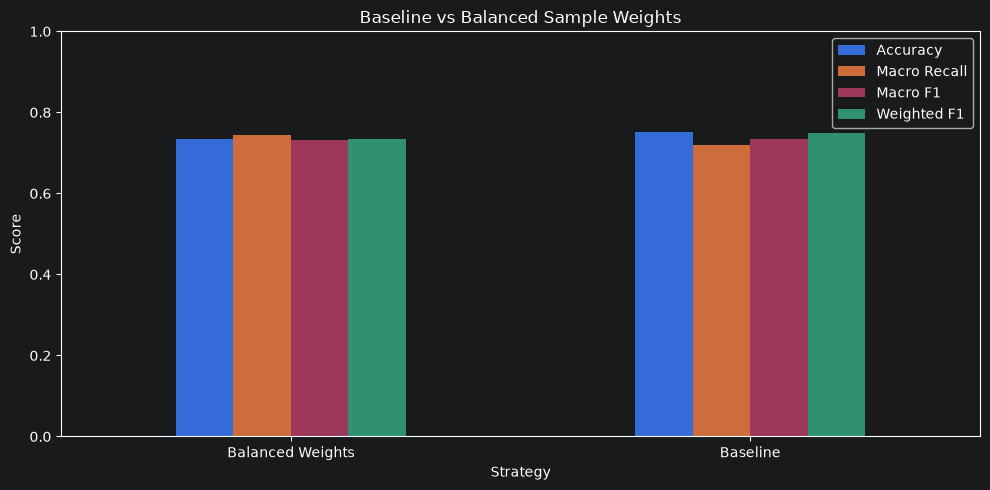

In [50]:

plot_metrics_a8 = [
    "Accuracy_Mean",
    "Macro_Recall_Mean",
    "Macro_F1_Mean",
    "Weighted_F1_Mean"
]

plot_labels_a8 = [
    "Accuracy",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

ax = imbalance_summary_df[plot_metrics_a8].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Baseline vs Balanced Sample Weights")
ax.set_xlabel("Strategy")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(plot_labels_a8)

plt.tight_layout()
plt.show()


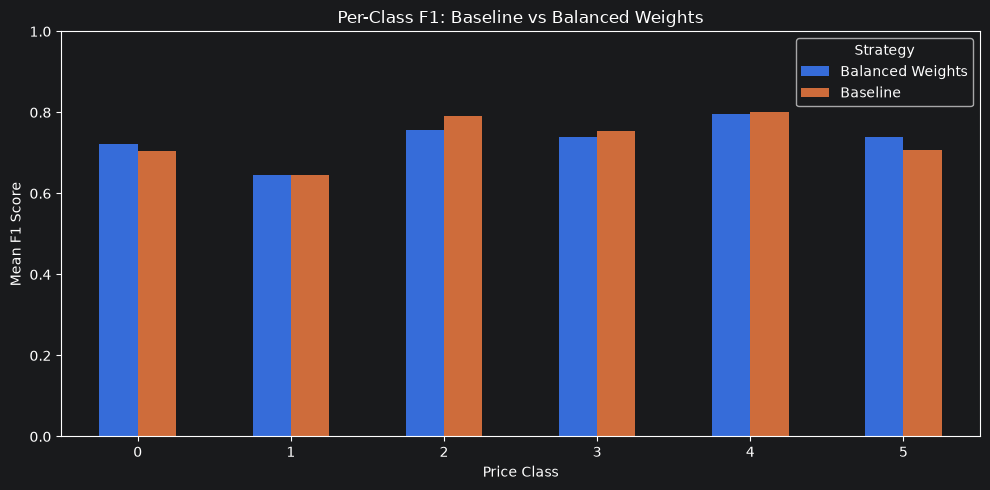

In [51]:

class_f1_plot = class_summary_df.pivot(
    index="Class",
    columns="Strategy",
    values="F1_Mean"
)

ax = class_f1_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Per-Class F1: Baseline vs Balanced Weights")
ax.set_xlabel("Price Class")
ax.set_ylabel("Mean F1 Score")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()
